# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [22]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt


torch.manual_seed(42)

## Step 2 — Upload the dataset

In [23]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [13]:
!pip install tensorflow

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl (351.2 MB)


In [25]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [26]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [27]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

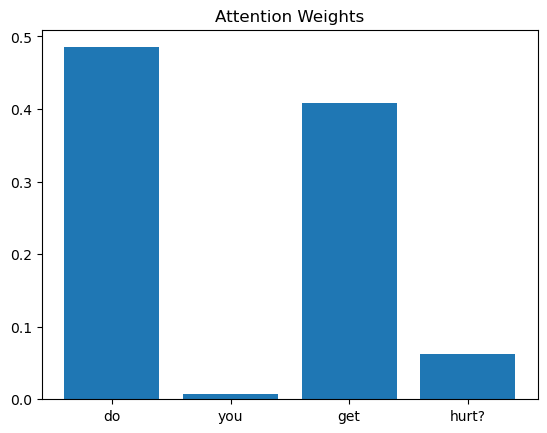

In [28]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest attention word: do
Function word - not the main meaning
Highest attention content word: get

Question: are you old?
Highest attention word: are
Function word - not the main meaning
Highest attention content word: old?

Question: will you ask me anything about myself
Highest attention word: about
Content word - may represent the main meaning
Highest attention content word: about



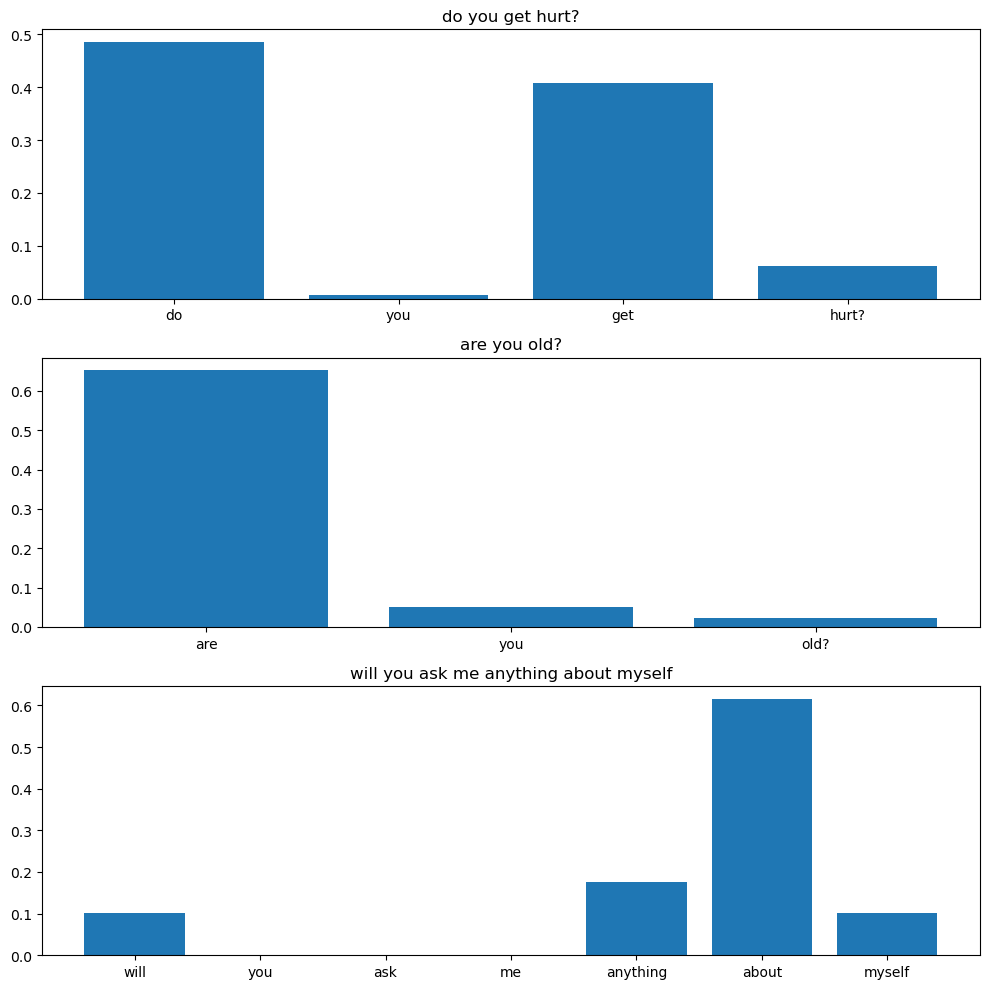

In [30]:

# Task 1 - Select 3 questions from different answer groups

question_indices = df.drop_duplicates(subset="answer_id").index[:3].tolist()

function_words = {"a", "an", "the", "and", "or", "to", "in", "on", "of",
                  "do", "does", "did", "is", "are", "am", "be", "you",
                  "your", "i", "we", "can", "could", "would", "have", "has"}

fig, axes = plt.subplots(3, 1, figsize=(10, 10))

for ax, idx in zip(axes, question_indices):
    question = df.loc[idx, "question"]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    scores = weights[0, :len(words)].tolist()

    ax.bar(words, scores)
    ax.set_title(question)

    top_word = words[scores.index(max(scores))]
    print(f"Question: {question}")
    print(f"Highest attention word: {top_word}")

    if top_word.lower().strip("?!.,") in function_words:
        print("Function word - not the main meaning")
    else:
        print("Content word - may represent the main meaning")

    content_words = [word for word in words
                     if word.lower().strip("?!.,") not in function_words]

    if content_words:
        top_content = max(content_words,
                          key=lambda word: scores[words.index(word)])
        print(f"Highest attention content word: {top_content}")

    print()

plt.tight_layout()
plt.show()


- Based on the attention plots, the model gives the higheest attention to "do" in all three questions. However, "do" is a function word and does not represent the main meaning of the questions. Words like "hurt", "fingers", and "breathe" provide more information about what each question is asking. This shows that the model does not always focus on the most meaningful words, and high attention weights do not necessarily indicate word importance.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

NameError: name 'plot_attention' is not defined

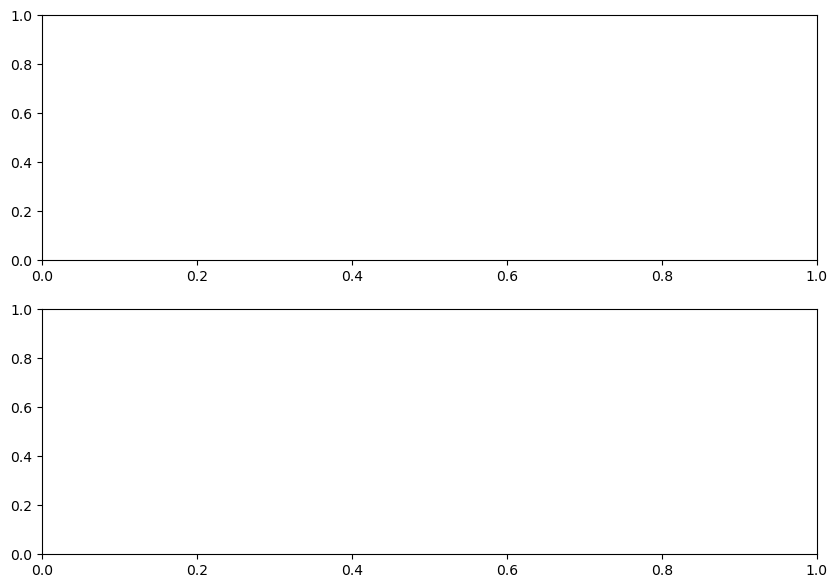

In [21]:
# Task 2: Two different wordings with the same meaning/answer group.
# In the provided dataset preview, both questions have answer_id 0:
#   0: "Do you get hurt?"
#   1: "Do you have fingers?"
# They both concern having a physical body; the recorded answer is
# "I don't have a body." Their wording is different.
pair_indices = [0, 1]
if df.loc[0, "answer_id"] != df.loc[1, "answer_id"]:
    raise ValueError("Choose two questions that share an answer_id in this dataset.")

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
task2_results = []
for ax, idx in zip(axes, pair_indices):
    top_word, top_weight, top_three = plot_attention(idx, ax=ax)
    task2_results.append((idx, top_word, top_weight, top_three))
plt.tight_layout()
plt.show()

for idx, top_word, top_weight, top_three in task2_results:
    print(f"Question: {df.loc[idx, 'question']}")
    print(f"Highest attention word: '{top_word}' (weight={top_weight:.4f})")
    print("Top 3 attended words:", ", ".join(top_three))
    print()

if task2_results[0][1] == task2_results[1][1]:
    print("Answer: The highest-attention word is the same in both questions. "
          "The model may be emphasizing a shared wording pattern.")
else:
    print("Answer: The highest-attention words are different. "
          "The model can assign attention to different words in questions "
          "associated with the same answer.")

shared_top_words = set(task2_results[0][3]) & set(task2_results[1][3])
print("Shared words among their top 3:", ", ".join(sorted(shared_top_words)) or "None")
print("Conclusion: Attention weights depend on the particular wording and the trained "
      "model. Similar intent does not require identical attention distributions, "
      "and attention weights alone are not causal explanations.")

- The two questions, “Do you get hurt?” and “Do you have fingers?”, use different wording but are linked to the same answer in the dataset: “I don't have a body.” Since the model calculates attention for each input separately, the words with the highest weights may be different even when the questions lead to the same response. If the top words overlap, the model may be picking up a shared language pattern; if they differ, it may be using different clues to identify the same answer category. This shows that attention can change depending on how a question is written, and the weights alone cannot fully explain the model's prediction.